# 판매자 챗봇 예측기 실험

챗봇 도구가 쓰는 예측기들을 **여러 모델로 비교하고 검증**하는 노트북이에요. 결과는 발표 자료와 챗봇 답변의 근거("이 예측은 평균 ±4일 오차")로 쓸 수 있어요.

| 실험 | 맞히는 것 | 챗봇 도구 |
| --- | --- | --- |
| A | 구매 시점에 지연 여부 | `delivery_estimate`, `coupon_advice` |
| B | 발송 시점을 바꾸면 지연 여부 (what-if) | `shipping_whatif` |
| C | 도착까지 며칠 (예측 구간 포함) | `delivery_estimate` |
| D | 1~2점 리뷰 (구매 시점 vs 배송 후) | `low_review_risk` |
| E | 다음 주 판매 수량 | `demand_forecast`, `reorder_quantity` |
| F | 리뷰 글로 나쁜 리뷰 맞히기 (텍스트) | `review_summary` 고도화, 딥러닝 파트 |

**공통 규칙**
- **시간 순서로 나눠요**: 학습 ~2017-12, 검증 2018-01~03, 시험 2018-04-01 ~ 2018-08-15 (전처리의 분석 기간 끝). 실제로는 과거로 학습해서 미래를 맞혀야 하니까 무작위로 섞지 않아요.
- **경계에 30일 간격을 둬요**: 12월 말에 산 주문의 배송 결과는 1월에야 나와서, 그대로 학습에 쓰면 검증 기간의 정보가 섞여요. 그래서 각 경계 **직전 30일 동안 구매한 주문은 통째로** 학습·검증에서 빼요 (학습: 2017-12-02 ~ 12-31 제외, 검증: 2018-03-02 ~ 03-31 제외). 결과가 늦게 나온 주문만 골라 빼면 늦게 오는 주문이 골라서 빠지는 편향이 생기니까, 결과와 상관없이 기간으로 빼요. 이렇게 하면 경계를 넘어 결과가 나오는 주문이 약 1%만 남아요.
- **모델은 검증 기간 성능으로 고르고, 시험 기간 성능은 보고만 해요.** 시험 점수를 보고 모델을 고르면 시험이 시험 역할을 못 해요.
- **미래 정보를 입력에 쓰지 않아요**: 특히 "판매자의 과거 지연율"은 그 주문 **이전에 이미 배송이 끝난** 주문만으로 계산해요.
- 모델: 기준선, 로지스틱/선형 회귀, 랜덤 포레스트, 그래디언트 부스팅(HGB), 신경망(MLP).

**준비물**: 전처리 결과 `olist_mart` 폴더(또는 `olist_mart.zip`). CPU로 10~15분 걸려요.

## 0. 준비

In [1]:
import os, sys, json, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
# 저장소(jc020230/BDA)의 preprocessing/ 폴더를 찾고, 노트북만 열었으면 저장소를 내려받기
import subprocess
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/jc020230/BDA.git', 'BDA'], check=True)
    os.chdir('BDA')
MART = next((p for p in ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart'] if os.path.exists(f'{p}/orders_mart.parquet')), None)
if MART is None:
    z = next(p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p))
    zipfile.ZipFile(z).extractall('.'); MART = 'olist_mart'
OUT = f'{MART}/experiments'; os.makedirs(OUT, exist_ok=True)

# 한글 폰트 (seller_tools.py가 있으면 그 함수를 쓰고, 없으면 간단히 설정)
try:
    from seller_tools import setup_korean_font; setup_korean_font()
except Exception:
    import matplotlib.font_manager as fm, glob, subprocess, urllib.request
    if IN_COLAB: subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    f = [x for x in fm.findSystemFonts() + glob.glob(os.path.expanduser('~/.fonts/*.ttf')) if 'NanumGothic' in x and 'Bold' not in x and 'Coding' not in x]
    if f: fm.fontManager.addfont(f[0]); plt.rc('font', family=fm.FontProperties(fname=f[0]).get_name())
    plt.rc('axes', unicode_minus=False)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
REPORT = {}
print('데이터:', MART, '| 결과 저장:', OUT)

데이터: preprocessing | 결과 저장: preprocessing/experiments


## 1. 실험용 표 만들기
한 행 = (주문, 판매자). 배송이 끝났고 시간 값이 정상인 주문만 써요.

In [2]:
osm = pd.read_parquet(f'{MART}/order_seller_mart.parquet')
om = pd.read_parquet(f'{MART}/orders_mart.parquet')
items = pd.read_parquet(f'{MART}/item_mart.parquet')

d = osm[osm.valid_times & osm.in_period]
if 'weight_g' not in d.columns:      # 전처리 1판이면 무게·부피를 여기서 계산 (2판에는 이미 있음)
    wv = items.groupby(['order_id', 'seller_id']).agg(weight_g=('product_weight_g', 'sum'), volume_cm3=('volume_cm3', 'sum')).reset_index()
    d = d.merge(wv, on=['order_id', 'seller_id'], how='left')
d = (d
       .merge(om[['order_id', 'review_answer_timestamp']], on='order_id', how='left')
       .sort_values('order_purchase_timestamp').reset_index(drop=True))
ts = d.order_purchase_timestamp
d['month'], d['weekday'], d['hour'] = ts.dt.month, ts.dt.dayofweek, ts.dt.hour
d['same_state'] = d.same_state.astype(int)
d['late'] = d.late.astype(int)
d['low_review'] = d.low_review.astype('float')
d['ship_late'] = d.ship_late.astype(int)
print(d.shape, '| 지연 비율:', round(d.late.mean(), 3))

(93957, 52) | 지연 비율: 0.069


### 판매자 과거 이력 (미래 정보 누수 없이)
"이 판매자는 전에 얼마나 늦었나"는 좋은 입력이지만, 그냥 계산하면 **아직 배송도 안 끝난 주문의 결과**가 섞여요. 그래서 `merge_asof`로 **구매 시각 이전에 배송이 끝난 주문**, **구매 시각 이전에 달린 리뷰**만 세요.

In [3]:
def past_stats(events, time_col, value_col, prefix):
    """판매자별로 time_col 시각까지 끝난 사건의 누적 개수·합 → 각 주문의 구매 시각 기준으로 붙이기"""
    e = events[['seller_id', time_col, value_col]].dropna().sort_values(time_col).copy()
    e[f'{prefix}_n'] = e.groupby('seller_id').cumcount() + 1
    e[f'{prefix}_sum'] = e.groupby('seller_id')[value_col].cumsum()
    left = d[['seller_id', 'order_purchase_timestamp']].reset_index().sort_values('order_purchase_timestamp')
    m = pd.merge_asof(left, e[['seller_id', time_col, f'{prefix}_n', f'{prefix}_sum']].sort_values(time_col),
                      left_on='order_purchase_timestamp', right_on=time_col, by='seller_id', direction='backward', allow_exact_matches=False)
    return m.set_index('index').sort_index()

pl = past_stats(d, 'order_delivered_customer_date', 'late', 'past_deliv')
pr = past_stats(d, 'review_answer_timestamp', 'review_score', 'past_rev')
d['seller_past_orders'] = pl.past_deliv_n.fillna(0)
d['seller_past_late_rate'] = pl.past_deliv_sum / pl.past_deliv_n
d['seller_past_score'] = pr.past_rev_sum / pr.past_rev_n
d[['seller_past_orders', 'seller_past_late_rate', 'seller_past_score']].describe().round(3)

,seller_past_orders,seller_past_late_rate,seller_past_score
count,93957.000,88645.000,87934.000
mean,167.044,0.044,4.183
std,277.857,0.064,0.423
min,0.000,0.000,1.000
25%,12.000,0.000,4.000
50%,51.000,0.031,4.203
75%,179.000,0.061,4.400
max,1724.000,1.000,5.000


In [4]:
# 시간 순서 분할
split = np.select([d.order_purchase_timestamp < '2018-01-01', d.order_purchase_timestamp < '2018-04-01'], ['train', 'valid'], 'test')
VALID_START, TEST_START_ = pd.Timestamp('2018-01-01'), pd.Timestamp('2018-04-01')
GAP = pd.Timedelta(days=30)   # 구매→도착 95%가 29일 안이라 30일
# 경계 직전 30일에 구매한 주문은 결과와 상관없이 통째로 뺌 (늦은 주문만 골라 빠지는 편향 방지)
gap = ((split == 'train') & (d.order_purchase_timestamp >= VALID_START - GAP)) | ((split == 'valid') & (d.order_purchase_timestamp >= TEST_START_ - GAP))
print('경계 직전 30일 구매라서 빠진 주문:', int(gap.sum()), '(학습', int((gap & (split == 'train')).sum()), '/ 검증', int((gap & (split == 'valid')).sum()), ')')
d, split = d[~gap].copy(), split[~gap.to_numpy()]
left = ((split == 'train') & (d.order_delivered_customer_date >= VALID_START)).sum() / max((split == 'train').sum(), 1)
print(f'남은 학습 주문 중 검증 시작 뒤에 도착한 비율: {left:.2%}')
d['split'] = split
print(d.groupby('split').agg(rows=('late', 'size'), late_rate=('late', 'mean'), low_rate=('low_review', 'mean')).round(3))

경계 직전 30일 구매라서 빠진 주문: 12124 (학습 5300 / 검증 6824 )
남은 학습 주문 중 검증 시작 뒤에 도착한 비율: 0.90%
        rows  late_rate  low_rate
split                            
test   29322      0.046     0.113
train  38488      0.054     0.121
valid  14023      0.100     0.172


**주의**: 검증 기간(2018년 1~3월)은 지연율이 유난히 높고, 시험 기간(4~8월)은 낮아요. 기간마다 상황이 달라서, 과거로 학습한 모델이 미래에 잘 맞는지 보는 실험으로는 오히려 좋은 조건이에요.

## 2. 공통 실험 함수

In [5]:
CAT = ['customer_state', 'seller_state', 'category_en']
F_PURCHASE = ['promised_days', 'dist_km', 'same_state', 'month', 'weekday', 'hour', 'n_items', 'price', 'freight_value',
              'weight_g', 'volume_cm3', 'seller_past_orders', 'seller_past_late_rate', 'seller_past_score'] + CAT

def prep_linear(num):
    return ColumnTransformer([('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
                              ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', min_frequency=20)), CAT)])
def prep_tree(num):
    return ColumnTransformer([('num', SimpleImputer(strategy='median'), num),
                              ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)), CAT)])
def to_cat(X):
    X = X.copy()
    for c in CAT: X[c] = X[c].astype('category')
    return X

def classifiers(feats, mono=None):
    num = [f for f in feats if f not in CAT]
    hgb_kw = dict(max_iter=300, learning_rate=0.06, categorical_features='from_dtype', random_state=0)
    if mono: hgb_kw['monotonic_cst'] = mono
    return {
        '로지스틱 회귀': (make_pipeline(prep_linear(num), LogisticRegression(max_iter=2000, C=0.5)), False),
        '랜덤 포레스트': (make_pipeline(prep_tree(num), RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=0)), False),
        'HGB (부스팅)': (HistGradientBoostingClassifier(**hgb_kw), True),
        '신경망 (MLP)': (make_pipeline(prep_linear(num), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=0)), False),
    }

def run_classification(name, data, feats, target, mono=None):
    tr, va, te = [data[data.split == s] for s in ['train', 'valid', 'test']]
    rows, fitted = [], {}
    base = tr[target].mean()
    rows.append({'model': '기준선 (평균 비율)', 'valid_auc': 0.5, 'test_auc': 0.5, 'test_pr_auc': te[target].mean(),
                 'test_brier': brier_score_loss(te[target], np.full(len(te), base)), 'fit_sec': 0})
    for mname, (model, native_cat) in classifiers(feats, mono).items():
        t0 = time.time()
        Xtr, Xva, Xte = [(to_cat(x[feats]) if native_cat else x[feats]) for x in (tr, va, te)]
        model.fit(Xtr, tr[target])
        pva, pte = model.predict_proba(Xva)[:, 1], model.predict_proba(Xte)[:, 1]
        rows.append({'model': mname, 'valid_auc': roc_auc_score(va[target], pva), 'test_auc': roc_auc_score(te[target], pte),
                     'test_pr_auc': average_precision_score(te[target], pte), 'test_brier': brier_score_loss(te[target], pte),
                     'fit_sec': round(time.time() - t0, 1)})
        fitted[mname] = (model, native_cat, pte)
    res = pd.DataFrame(rows).set_index('model').round(4)
    REPORT[name] = res.reset_index().to_dict('records')
    return res, fitted, te

def bar(res, col, title, ref=None):
    ax = res[col].plot(kind='barh', figsize=(7, 3), color='tab:blue'); ax.set_title(title); ax.set_xlabel(col)
    if ref is not None: ax.axvline(ref, color='gray', ls='--')
    ax.set_xlim(left=min(0.45, res[col].min() - 0.02)) if 'auc' in col else None
    plt.tight_layout(); plt.show()

## 실험 A. 구매 시점에 지연 여부 맞히기
- **AUC**: 늦을 주문과 안 늦을 주문을 얼마나 잘 줄 세우나 (0.5 = 찍기, 1 = 완벽)
- **PR-AUC**: 지연이 6%뿐이라 "늦을 주문을 골라냈을 때 실제로 늦은 비율"을 같이 봐요. 기준선은 지연 비율 그 자체예요.
- **Brier**: 예측 확률과 실제(0/1)의 차이. 쿠폰 계산처럼 **확률 값 자체**를 쓰는 곳에서 중요해요 (작을수록 좋음).

In [6]:
resA, fitA, teA = run_classification('A_late_purchase_time', d, F_PURCHASE, 'late')
resA

,valid_auc,test_auc,test_pr_auc,test_brier,fit_sec
model,,,,,
기준선 (평균 비율),0.5000,0.5000,0.0464,0.0443,0.0
로지스틱 회귀,0.7070,0.7103,0.0938,0.0434,0.5
랜덤 포레스트,0.6046,0.6740,0.0777,0.0449,16.8
HGB (부스팅),0.6495,0.6831,0.0991,0.0440,1.0
신경망 (MLP),0.5506,0.6647,0.0938,0.0439,3.6


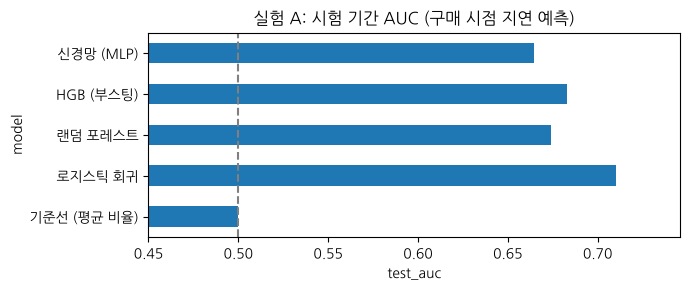

In [7]:
bar(resA, 'test_auc', '실험 A: 시험 기간 AUC (구매 시점 지연 예측)', ref=0.5)

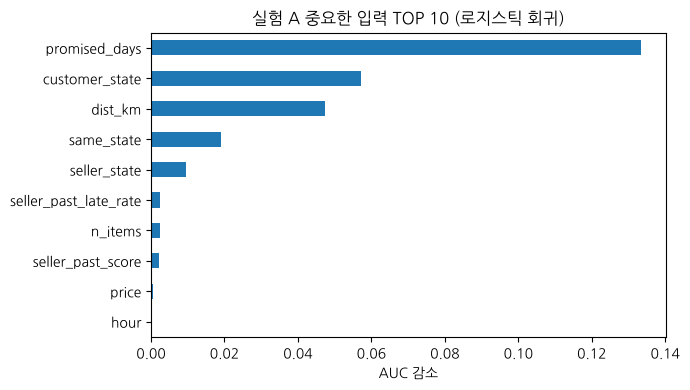

In [8]:
# 가장 좋은 모델: 무엇을 보고 맞히나 (permutation importance: 그 열을 섞었을 때 AUC가 얼마나 떨어지나)
best = resA.drop('기준선 (평균 비율)').valid_auc.idxmax()   # 검증 기간으로 고른 모델
model, native, _ = fitA[best]
sub = teA.sample(5000, random_state=0)
pi = permutation_importance(model, to_cat(sub[F_PURCHASE]) if native else sub[F_PURCHASE], sub.late, scoring='roc_auc', n_repeats=3, random_state=0)
imp = pd.Series(pi.importances_mean, index=F_PURCHASE).sort_values()
imp.tail(10).plot(kind='barh', figsize=(7, 4), title=f'실험 A 중요한 입력 TOP 10 ({best})'); plt.xlabel('AUC 감소'); plt.tight_layout(); plt.show()

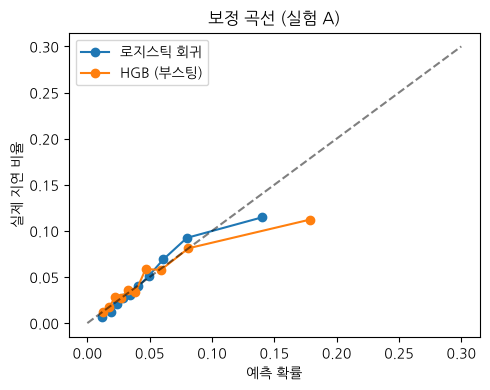

In [9]:
# 확률이 믿을 만한가 (보정 곡선): 대각선에 가까울수록 "10%라고 하면 실제로 10%쯤 늦는다"
fig, ax = plt.subplots(figsize=(5, 4))
for mname in ['로지스틱 회귀', 'HGB (부스팅)']:
    frac, mean_p = calibration_curve(teA.late, fitA[mname][2], n_bins=10, strategy='quantile')
    ax.plot(mean_p, frac, marker='o', label=mname)
ax.plot([0, 0.3], [0, 0.3], 'k--', alpha=0.5); ax.set_xlabel('예측 확률'); ax.set_ylabel('실제 지연 비율'); ax.set_title('보정 곡선 (실험 A)'); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
# 월별로 보면: 기간마다 성능이 흔들리는지
te = teA.assign(p=fitA[best][2])
monthly = te.groupby(te.order_purchase_timestamp.dt.to_period('M')).apply(lambda g: pd.Series({'orders': len(g), 'late_rate': g.late.mean(), 'auc': roc_auc_score(g.late, g.p) if g.late.nunique() > 1 else np.nan}))
monthly.round(3)

,orders,late_rate,auc
order_purchase_timestamp,,,
2018-04,6524.0,0.046,0.784
2018-05,6792.0,0.065,0.688
2018-06,6082.0,0.012,0.767
2018-07,5686.0,0.036,0.655
2018-08,4238.0,0.082,0.591


## 실험 B. 발송 what-if (발송까지 걸린 시간을 입력에 추가)
챗봇의 `shipping_whatif`가 쓰는 모델이에요. 발송 처리 시간(`handling_days`)은 판매자가 바꿀 수 있는 값이라, "n일 뒤에 보내면?"을 물을 수 있어요.

HGB에 **단조 제약**(발송이 늦을수록 지연 확률이 내려가지 않게)을 건 것과 안 건 것을 비교해요. 제약을 걸어도 성능이 비슷하면, what-if 결과가 상식에 맞게 나오는 제약 버전을 쓰는 게 좋아요.

           test_auc  test_pr_auc
model                           
HGB 제약 없음    0.7704       0.2980
HGB 단조 제약    0.7742       0.2902


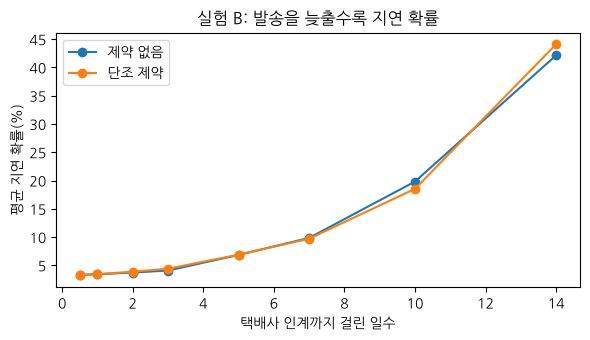

In [11]:
F_SHIP = ['handling_days'] + F_PURCHASE
tr, va, te = [d[d.split == s] for s in ['train', 'valid', 'test']]
rowsB, curves = [], {}
for label, mono in [('제약 없음', None), ('단조 제약', [1] + [0] * (len(F_SHIP) - 1))]:
    kw = dict(max_iter=300, learning_rate=0.06, categorical_features='from_dtype', random_state=0)
    if mono: kw['monotonic_cst'] = mono
    m = HistGradientBoostingClassifier(**kw).fit(to_cat(tr[F_SHIP]), tr.late)
    p = m.predict_proba(to_cat(te[F_SHIP]))[:, 1]
    rowsB.append({'model': f'HGB {label}', 'test_auc': roc_auc_score(te.late, p), 'test_pr_auc': average_precision_score(te.late, p)})
    sample = to_cat(te[F_SHIP].sample(2000, random_state=0))
    grid = [0.5, 1, 2, 3, 5, 7, 10, 14]
    curves[label] = [m.predict_proba(sample.assign(handling_days=h))[:, 1].mean() for h in grid]
resB = pd.DataFrame(rowsB).set_index('model').round(4)
REPORT['B_late_whatif'] = resB.reset_index().to_dict('records')
print(resB)
fig, ax = plt.subplots(figsize=(6, 3.5))
for label, c in curves.items(): ax.plot(grid, np.array(c) * 100, marker='o', label=label)
ax.set_xlabel('택배사 인계까지 걸린 일수'); ax.set_ylabel('평균 지연 확률(%)'); ax.set_title('실험 B: 발송을 늦출수록 지연 확률'); ax.legend()
plt.tight_layout(); plt.show()

## 실험 C. 도착까지 며칠 걸릴까 (회귀 + 예측 구간)
- **MAE**: 평균 몇 일 틀리나
- 비교 기준: **Olist 약속일**(일부러 넉넉하게 잡아서 오차가 큼), **경로 중앙값**(판매자 주 → 고객 주 조합의 과거 중앙값)
- **90% 구간**: 분위수 회귀로 "90% 확률로 며칠 안에 온다"를 만들고, 시험 기간에 실제로 90% 근처가 그 안에 들어오는지 확인

In [12]:
tr, va, te = [d[d.split == s] for s in ['train', 'valid', 'test']]
num = [f for f in F_PURCHASE if f not in CAT]
rowsC = []
rowsC.append({'model': 'Olist 약속일 그대로', 'valid_mae': mean_absolute_error(va.days, va.promised_days), 'test_mae': mean_absolute_error(te.days, te.promised_days)})
route = tr.groupby(['seller_state', 'customer_state']).days.median()
def route_pred(x):
    p = x.set_index(['seller_state', 'customer_state']).index.map(route).astype(float)
    return np.where(np.isnan(p), tr.days.median(), p)
rowsC.append({'model': '경로(주→주) 중앙값', 'valid_mae': mean_absolute_error(va.days, route_pred(va)), 'test_mae': mean_absolute_error(te.days, route_pred(te))})
regs = {
    '선형 회귀': (make_pipeline(prep_linear(num), LinearRegression()), False),
    '랜덤 포레스트': (make_pipeline(prep_tree(num), RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=0)), False),
    'HGB (부스팅)': (HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, categorical_features='from_dtype', random_state=0), True),
    '신경망 (MLP)': (make_pipeline(prep_linear(num), MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=0)), False),
}
predsC = {}
for mname, (model, native) in regs.items():
    t0 = time.time()
    model.fit(to_cat(tr[F_PURCHASE]) if native else tr[F_PURCHASE], tr.days)
    pv = model.predict(to_cat(va[F_PURCHASE]) if native else va[F_PURCHASE])
    p = model.predict(to_cat(te[F_PURCHASE]) if native else te[F_PURCHASE]); predsC[mname] = p
    rowsC.append({'model': mname, 'valid_mae': mean_absolute_error(va.days, pv), 'test_mae': mean_absolute_error(te.days, p), 'fit_sec': round(time.time() - t0, 1)})
resC = pd.DataFrame(rowsC).set_index('model').round(3)
REPORT['C_delivery_days'] = resC.reset_index().to_dict('records')
resC

,valid_mae,test_mae,fit_sec
model,,,
Olist 약속일 그대로,12.535,13.063,NaN
경로(주→주) 중앙값,6.694,4.280,NaN
선형 회귀,6.334,4.560,0.4
랜덤 포레스트,6.282,4.622,47.8
HGB (부스팅),6.291,4.724,1.1
신경망 (MLP),6.585,4.692,4.7


90% 상한 안에 실제로 들어온 비율: 0.922 (목표 0.9)
상한은 예측값보다 보통 몇 일 더 긴가: 5.6
참고: Olist 약속일 안에 들어온 비율: 0.939


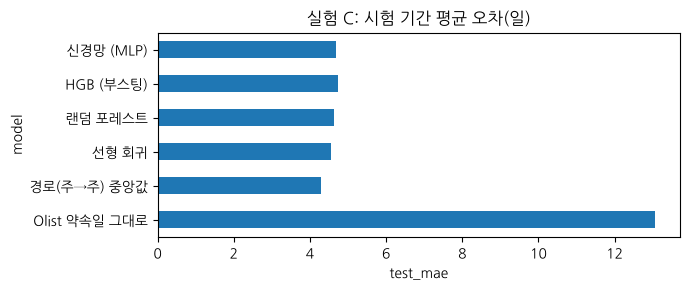

In [13]:
# 90% 예측 구간: 분위수 0.9 회귀
q90 = HistGradientBoostingRegressor(loss='quantile', quantile=0.9, max_iter=300, learning_rate=0.06, categorical_features='from_dtype', random_state=0)
q90.fit(to_cat(tr[F_PURCHASE]), tr.days)
up = q90.predict(to_cat(te[F_PURCHASE]))
interval = {'coverage_90': float((te.days <= up).mean()), 'median_upper_minus_point': float(np.median(up - predsC['HGB (부스팅)'])),
            'promised_coverage': float((te.days <= te.promised_days).mean())}
REPORT['C_interval'] = interval
print('90% 상한 안에 실제로 들어온 비율:', round(interval['coverage_90'], 3), '(목표 0.9)')
print('상한은 예측값보다 보통 몇 일 더 긴가:', round(interval['median_upper_minus_point'], 1))
print('참고: Olist 약속일 안에 들어온 비율:', round(interval['promised_coverage'], 3))
bar(resC[['test_mae']], 'test_mae', '실험 C: 시험 기간 평균 오차(일)')

## 실험 D. 1~2점 리뷰 맞히기: 구매 시점 vs 배송 후
챗봇의 `low_review_risk`는 배송 상황을 알고 나서 위험 주문을 골라요. 배송 정보가 들어가면 얼마나 좋아지는지 봐요.

In [14]:
dd = d.dropna(subset=['low_review']).copy(); dd['low_review'] = dd.low_review.astype(int)
# 리뷰 실험도 위의 30일 간격이 이미 적용돼 있어요 (구매→리뷰 답변 95%가 31일 안)
print('학습 주문 중 검증 시작 뒤에 리뷰 답변이 달린 비율:', f"{((dd.split == 'train') & (dd.review_answer_timestamp >= VALID_START)).mean() / max((dd.split == 'train').mean(), 1e-9):.2%}")
F_AFTER = F_PURCHASE + ['handling_days', 'transit_days', 'days', 'delay_days', 'ship_late']
rowsD = []
for label, feats in [('구매 시점 정보만', F_PURCHASE), ('배송 후 정보 추가', F_AFTER)]:
    tr, va, te = dd[dd.split == 'train'], dd[dd.split == 'valid'], dd[dd.split == 'test']
    for mname, model, native in [('로지스틱 회귀', make_pipeline(prep_linear([f for f in feats if f not in CAT]), LogisticRegression(max_iter=2000, C=0.5)), False),
                                 ('HGB (부스팅)', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, categorical_features='from_dtype', random_state=0), True)]:
        model.fit(to_cat(tr[feats]) if native else tr[feats], tr.low_review)
        pv = model.predict_proba(to_cat(va[feats]) if native else va[feats])[:, 1]
        p = model.predict_proba(to_cat(te[feats]) if native else te[feats])[:, 1]
        rowsD.append({'features': label, 'model': mname, 'valid_auc': roc_auc_score(va.low_review, pv),
                      'test_auc': roc_auc_score(te.low_review, p), 'test_pr_auc': average_precision_score(te.low_review, p)})
resD = pd.DataFrame(rowsD).round(4)
REPORT['D_low_review'] = resD.to_dict('records')
print('시험 기간 1~2점 비율:', round(dd[dd.split == 'test'].low_review.mean(), 3))
resD

학습 주문 중 검증 시작 뒤에 리뷰 답변이 달린 비율: 0.74%


시험 기간 1~2점 비율: 0.113


,features,model,valid_auc,test_auc,test_pr_auc
0,구매 시점 정보만,로지스틱 회귀,0.6225,0.5944,0.1595
1,구매 시점 정보만,HGB (부스팅),0.6191,0.6030,0.1595
2,배송 후 정보 추가,로지스틱 회귀,0.7570,0.6657,0.2596
3,배송 후 정보 추가,HGB (부스팅),0.7862,0.6897,0.3257


## 실험 E. 다음 주 판매 수량 (발주용 수요 예측)
판매자 × 카테고리의 주간 판매량을 2018-04-02 ~ 2018-08-27 각 주에 대해 **한 주 앞**만 예측해요 (그 주 직전까지의 데이터만 사용).

| 방법 | 설명 |
| --- | --- |
| 지난주 그대로 | 다음 주 = 이번 주 |
| 4주·8주 이동평균 | 최근 4주·8주 평균 |
| 지수가중평균(8주) | 최근 주에 더 큰 비중 (챗봇 도구의 기본 방법) |
| 지수가중평균 × 이벤트 | 위 값에 이벤트 주 배수 (**배수는 2017년 이벤트로만** 계산해서 미래 정보가 안 섞이게) |
| HGB (부스팅) | 지난 1~4주 판매, 이동평균, 카테고리, 이벤트, 월을 입력으로 쓰는 머신러닝 |

지표: **WAPE** = 전체 오차 합 ÷ 전체 판매량 합 (판매량이 0인 주가 많아서 MAPE 대신 써요), 편향 = 예측 합 ÷ 실제 합 − 1

In [15]:
weekly = pd.read_parquet(f'{MART}/sales_weekly_seller_cat.parquet')
daily = pd.read_parquet(f'{MART}/sales_daily.parquet')
events = pd.read_parquet(f'{MART}/events.parquet')
TEST_START = pd.Timestamp('2018-04-02')
weekly['key'] = weekly.seller_id + '|' + weekly.category_en
active = weekly[weekly.week_start < TEST_START].groupby('key').units.sum()
keys = active[active >= 20].index                       # 시험 전까지 20개 이상 판 판매자×카테고리만
W = weekly[weekly.key.isin(keys)].pivot_table(index='key', columns='week_start', values='units')   # 첫 판매 전은 NaN
cat_of = weekly.drop_duplicates('key').set_index('key').category_en
test_weeks = [w for w in W.columns if w >= TEST_START]
print('시계열 수:', len(keys), '| 시험 주 수:', len(test_weeks))

# 2017년 이벤트로만 카테고리별 배수 계산
piv = daily.pivot_table(index='purchase_date', columns='category_en', values='units', aggfunc='sum').fillna(0); piv['__all__'] = piv.sum(axis=1)
ev_days = set().union(*[set(pd.date_range(r.window_start, r.window_end)) for r in events.itertuples()])
mult = {}
for ev, g in events[events.date.dt.year == 2017].groupby('event'):
    rs = []
    for r in g.itertuples():
        w = piv.loc[r.window_start:r.window_end]
        base_idx = [x for x in pd.date_range(r.window_start - pd.Timedelta(days=28), r.window_start - pd.Timedelta(days=1)) if x not in ev_days and x in piv.index]
        b = piv.loc[base_idx]; rs.append((w.mean() / b.mean()).where(b.sum() >= 20))
    mult[ev] = pd.concat(rs, axis=1).mean(axis=1)
def week_multiple(week, cat):
    m = 1.0
    for r in events.itertuples():
        overlap = (min(week + pd.Timedelta(days=6), r.window_end) - max(week, r.window_start)).days + 1
        if overlap > 0 and r.event in mult:
            v = mult[r.event].get(cat, np.nan); v = mult[r.event]['__all__'] if pd.isna(v) else v
            m = max(m, (overlap * v + 7 - overlap) / 7)
    return m
print({k: round(float(v['__all__']), 2) for k, v in mult.items()})

시계열 수: 699 | 시험 주 수: 19
{'black_friday': 3.7, 'christmas': 0.72, 'fathers_day': 0.96, 'mothers_day': 1.31, 'valentines_day': 1.01}


In [16]:
# 통계적 방법들: 각 시험 주마다 그 직전까지의 값으로 예측
F = {}
F['지난주 그대로'] = W.shift(1, axis=1)
F['4주 이동평균'] = W.T.rolling(4, min_periods=1).mean().T.shift(1, axis=1)
F['8주 이동평균'] = W.T.rolling(8, min_periods=1).mean().T.shift(1, axis=1)
F['지수가중평균(8주)'] = W.T.ewm(span=8).mean().T.shift(1, axis=1)
evm = pd.DataFrame({w: [week_multiple(w, cat_of[k]) for k in W.index] for w in test_weeks}, index=W.index)
F['지수가중평균 × 이벤트'] = F['지수가중평균(8주)'][test_weeks] * evm

# HGB: 지난 주들의 판매로 다음 주 판매를 맞히는 표 만들기
def to_long(wide, name):
    """(시계열 × 주) 표 → (시계열, 주) 한 줄씩. NaN도 남김 (pandas 버전과 상관없이 동작)"""
    return wide.rename_axis(index='key', columns='week_start').reset_index().melt(id_vars='key', var_name='week_start', value_name=name).set_index(['key', 'week_start'])[name]
long = [to_long(W.shift(lag, axis=1), f'lag{lag}') for lag in range(1, 5)]
long += [to_long(F['4주 이동평균'], 'ma4'), to_long(F['8주 이동평균'], 'ma8'), to_long(F['지수가중평균(8주)'], 'ewm8'), to_long(W, 'y')]
T = pd.concat(long, axis=1).reset_index()
T = T.dropna(subset=['y', 'lag1'])
T['category_en'] = T.key.map(cat_of).astype('category'); T['month'] = T.week_start.dt.month
T['event_mult'] = [week_multiple(w, c) for w, c in zip(T.week_start, T.category_en.astype(str))]
FE = ['lag1', 'lag2', 'lag3', 'lag4', 'ma4', 'ma8', 'ewm8', 'category_en', 'month', 'event_mult']
VALID_START = pd.Timestamp('2018-01-01')
def evaluate(start, end):
    """start~end 주를 한 주 앞 예측으로 평가. HGB는 start 이전 주들로만 학습"""
    weeks = [w for w in W.columns if start <= w <= end]
    tr_, te_ = T[T.week_start < start], T[(T.week_start >= start) & (T.week_start <= end)]
    hgb = HistGradientBoostingRegressor(loss='poisson', max_iter=300, learning_rate=0.05, categorical_features='from_dtype', random_state=0).fit(tr_[FE], tr_.y)
    hp = pd.Series(hgb.predict(te_[FE]), index=pd.MultiIndex.from_frame(te_[['key', 'week_start']]))
    evm_ = pd.DataFrame({w: [week_multiple(w, cat_of[k]) for k in W.index] for w in weeks}, index=W.index)
    methods = {k: v[weeks] for k, v in F.items() if k != '지수가중평균 × 이벤트'}
    methods['지수가중평균 × 이벤트'] = F['지수가중평균(8주)'][weeks] * evm_
    actual = to_long(W[weeks], 'y'); out = {}
    for mname, fc in list(methods.items()) + [('HGB (부스팅)', None)]:
        pred = hp if fc is None else to_long(fc, 'p')
        pair = pd.concat([actual.rename('y'), pred.rename('p')], axis=1).dropna()
        out[mname] = {'WAPE': (pair.y - pair.p).abs().sum() / pair.y.sum(), 'bias': pair.p.sum() / pair.y.sum() - 1, 'n': len(pair)}
    return out, hp
val_res, _ = evaluate(VALID_START, TEST_START - pd.Timedelta(days=1))
test_res, hgb_pred = evaluate(TEST_START, W.columns.max())
rowsE = [{'method': m, 'valid_WAPE': val_res[m]['WAPE'], 'WAPE': test_res[m]['WAPE'], 'bias': test_res[m]['bias'], 'n': test_res[m]['n']} for m in test_res]
resE = pd.DataFrame(rowsE).set_index('method').round(3)
REPORT['E_demand'] = resE.reset_index().to_dict('records')
resE

,valid_WAPE,WAPE,bias,n
method,,,,
지난주 그대로,0.727,0.768,0.009,13281
4주 이동평균,0.693,0.728,0.045,13281
8주 이동평균,0.721,0.768,0.127,13281
지수가중평균(8주),0.685,0.747,0.120,13281
지수가중평균 × 이벤트,0.685,0.761,0.159,13281
HGB (부스팅),0.714,0.786,0.129,13281


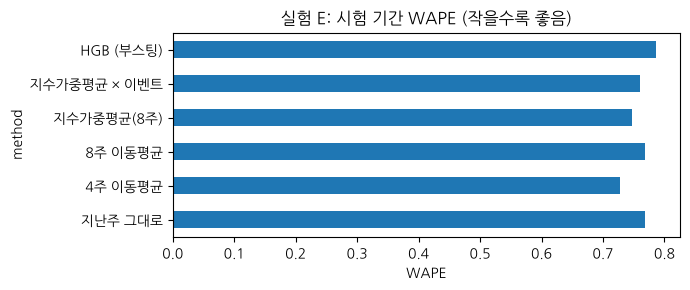

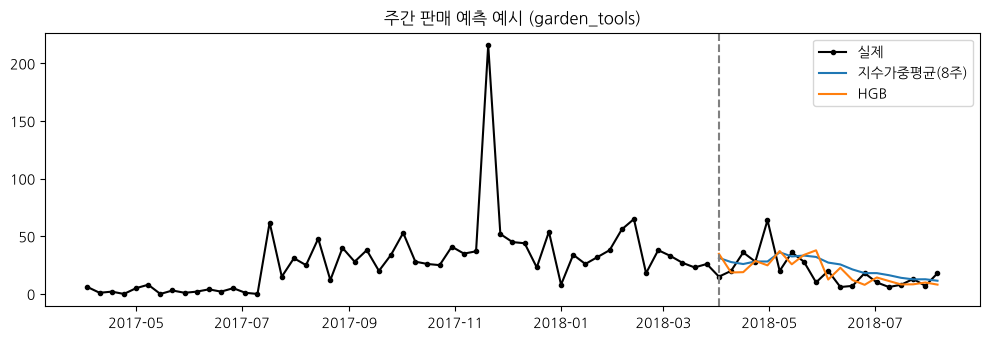

In [17]:
bar(resE, 'WAPE', '실험 E: 시험 기간 WAPE (작을수록 좋음)')
# 판매량이 가장 많은 시계열 하나로 예측 모양 보기
k = W.sum(axis=1).idxmax()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(W.columns, W.loc[k], marker='.', label='실제', color='k')
ax.plot(test_weeks, F['지수가중평균(8주)'].loc[k, test_weeks], label='지수가중평균(8주)')
ax.plot(test_weeks, hgb_pred.xs(k, level='key').reindex(test_weeks), label='HGB')
ax.axvline(TEST_START, color='gray', ls='--'); ax.set_title(f'주간 판매 예측 예시 ({cat_of[k]})'); ax.legend(); plt.tight_layout(); plt.show()

## 실험 F. 리뷰 글로 나쁜 리뷰(1~2점) 맞히기
리뷰 글이 있는 리뷰만 써요. 이건 "별점을 맞히는 것" 자체보다, **글 속 어떤 말이 불만 신호인지**를 보는 실험이에요. 챗봇의 리뷰 요약(현재 키워드 규칙)을 고도화하는 근거가 돼요.

- 기본: TF-IDF(단어·두 단어 묶음) + 로지스틱 회귀
- 딥러닝(선택): 포르투갈어 BERT(BERTimbau) 미세조정. Colab에서 **런타임 → 런타임 유형 → GPU**로 바꾸고 아래 `RUN_BERT = True`로 실행해요.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
rt = pd.read_parquet(f'{MART}/review_text.parquet')
rt = rt[rt.has_text & rt.in_period].dropna(subset=['msg_noaccent']).copy()
rt['low'] = (rt.review_score <= 2).astype(int)
rt['split'] = np.select([rt.review_creation_date < '2018-01-01', rt.review_creation_date < '2018-04-01'], ['train', 'valid'], 'test')
gap_t = ((rt.split == 'train') & (rt.review_creation_date >= pd.Timestamp('2018-01-01') - pd.Timedelta(days=30))) | \
        ((rt.split == 'valid') & (rt.review_creation_date >= pd.Timestamp('2018-04-01') - pd.Timedelta(days=30)))
print('텍스트 실험 경계 직전 30일 리뷰 제외:', int(gap_t.sum())); rt = rt[~gap_t]
trT, teT = rt[rt.split == 'train'], rt[rt.split == 'test']
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000, sublinear_tf=True)
Xtr, Xte = vec.fit_transform(trT.msg_noaccent), vec.transform(teT.msg_noaccent)
lr = LogisticRegression(max_iter=2000, C=2.0).fit(Xtr, trT.low)
pT = lr.predict_proba(Xte)[:, 1]
REPORT['F_text_tfidf'] = {'test_auc': float(roc_auc_score(teT.low, pT)), 'test_pr_auc': float(average_precision_score(teT.low, pT)),
                          'test_low_rate': float(teT.low.mean()), 'n_train': int(len(trT)), 'n_test': int(len(teT))}
print(REPORT['F_text_tfidf'])
coef = pd.Series(lr.coef_[0], index=vec.get_feature_names_out())
print('\n나쁜 리뷰 쪽으로 가장 강한 표현:', list(coef.nlargest(15).index))
print('좋은 리뷰 쪽으로 가장 강한 표현:', list(coef.nsmallest(15).index))

텍스트 실험 경계 직전 30일 리뷰 제외: 6375


{'test_auc': 0.951333703820884, 'test_pr_auc': 0.8403813883312374, 'test_low_rate': 0.25615690901047045, 'n_train': 14570, 'n_test': 13562}

나쁜 리뷰 쪽으로 가장 강한 표현: ['nao', 'nao recomendo', 'comprei', 'nem', 'pessimo', 'pessima', 'nao chegou', 'quero', 'demora', 'nao recebi', 'falta', 'horrivel', 'ruim', 'fiz', 'errado']
좋은 리뷰 쪽으로 가장 강한 표현: ['rapida', 'parabens', 'recomendo', 'rapido', 'excelente', 'so nao', 'lindo', 'antes', 'amei', 'adorei', 'bem', 'tudo', 'otima', 'boa', 'otimo']


In [19]:
RUN_BERT = False   # Colab GPU에서 True로 바꿔 실행 (20~40분). 이 노트북을 만들 때는 실행하지 않았어요.
if RUN_BERT:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    name = 'neuralmind/bert-base-portuguese-cased'
    tok = AutoTokenizer.from_pretrained(name)
    bert = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2).to('cuda')
    def batches(df, shuffle):
        enc = tok(list(df.review_comment_message.fillna('')), truncation=True, max_length=128, padding='max_length', return_tensors='pt')
        ds = torch.utils.data.TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(df.low.values))
        return DataLoader(ds, batch_size=32, shuffle=shuffle)
    opt = torch.optim.AdamW(bert.parameters(), lr=2e-5)
    bert.train()
    for epoch in range(2):
        for ids, mask, y in batches(trT, True):
            out = bert(input_ids=ids.cuda(), attention_mask=mask.cuda(), labels=y.cuda())
            out.loss.backward(); opt.step(); opt.zero_grad()
    bert.eval(); probs = []
    with torch.no_grad():
        for ids, mask, y in batches(teT, False):
            probs.append(torch.softmax(bert(input_ids=ids.cuda(), attention_mask=mask.cuda()).logits, -1)[:, 1].cpu().numpy())
    pB = np.concatenate(probs)
    REPORT['F_text_bertimbau'] = {'test_auc': float(roc_auc_score(teT.low, pB)), 'test_pr_auc': float(average_precision_score(teT.low, pB))}
    print(REPORT['F_text_bertimbau'])

## 7. 결과 저장

In [20]:
def clean(x):
    if isinstance(x, dict): return {k: clean(v) for k, v in x.items()}
    if isinstance(x, list): return [clean(v) for v in x]
    if isinstance(x, (np.floating, float)): return None if np.isnan(x) else round(float(x), 4)
    if isinstance(x, np.integer): return int(x)
    return x
with open(f'{OUT}/model_report.json', 'w', encoding='utf-8') as f:
    json.dump(clean(REPORT), f, ensure_ascii=False, indent=1)
print('저장:', f'{OUT}/model_report.json')
dA = resA.drop('기준선 (평균 비율)'); bestA = dA.valid_auc.idxmax()
bestC = resC.valid_mae.idxmin()
dD = resD[resD.features == '배송 후 정보 추가'].set_index('model'); bestD = dD.valid_auc.idxmax()
bestE = resE.valid_WAPE.idxmin()
summary = pd.DataFrame({
    '실험': ['A 지연(구매 시점)', 'B 지연 what-if', 'C 도착일', 'D 1~2점(배송 후)', 'E 수요', 'F 리뷰 글'],
    '검증 기간으로 고른 방법': [bestA, 'HGB 단조 제약 (what-if가 상식에 맞게)', bestC, bestD, bestE, 'TF-IDF + 로지스틱'],
    '그 방법의 시험 성능': [f"AUC {dA.loc[bestA, 'test_auc']:.3f}", f"AUC {resB.loc['HGB 단조 제약', 'test_auc']:.3f}", f"MAE {resC.loc[bestC, 'test_mae']:.2f}일",
                     f"AUC {dD.loc[bestD, 'test_auc']:.3f}", f"WAPE {resE.loc[bestE, 'WAPE']:.3f}", f"AUC {REPORT['F_text_tfidf']['test_auc']:.3f}"],
})
REPORT['summary'] = summary.to_dict('records')
with open(f'{OUT}/model_report.json', 'w', encoding='utf-8') as f:
    json.dump(clean(REPORT), f, ensure_ascii=False, indent=1)
summary

저장: preprocessing/experiments/model_report.json


,실험,검증 기간으로 고른 방법,그 방법의 시험 성능
0,A 지연(구매 시점),로지스틱 회귀,AUC 0.710
1,B 지연 what-if,HGB 단조 제약 (what-if가 상식에 맞게),AUC 0.774
2,C 도착일,랜덤 포레스트,MAE 4.62일
3,D 1~2점(배송 후),HGB (부스팅),AUC 0.690
4,E 수요,지수가중평균(8주),WAPE 0.747
5,F 리뷰 글,TF-IDF + 로지스틱,AUC 0.951


## 결과 읽는 법과 챗봇에 쓰는 법
- 챗봇이 예측을 말할 때 **오차를 같이 말하게** 하세요. 예: "약 7일 걸려요 (이 예측은 평균 ±N일 틀려요, 90% 확률로 M일 안)". 숫자는 `model_report.json`에서 가져오면 돼요.
- 수요 예측은 판매가 적은 판매자일수록 크게 틀려요. 챗봇의 `demand_forecast`가 돌려주는 `confidence`와 `backtest_mae_8w`를 같이 보여주세요.
- 기간마다 지연 상황이 달라서(2018년 2~3월 급증), 시험 기간 성능이 학습 기간보다 낮게 나오는 게 자연스러워요. 발표 때 "과거로 학습해 미래로 시험했다"는 점을 강조하세요.